# Privacidad diferencial — CrediFácil

Notebook de la sección 6.8 del informe (`docs/index.md`). Objetivo: implementar y evaluar privacidad diferencial sobre agregados sensibles de `application_train_clean.csv`, con `diffprivlib` (IBM), barriendo varios valores de epsilon para mostrar el trade-off privacidad/utilidad.

## Fase 0 — Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from diffprivlib.tools import mean

df = pd.read_csv("../dataset/application_train_clean.csv")
df.shape

(307507, 80)

In [2]:
df.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'FLAG_MOBIL',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'OCCUPATION_TYPE',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'WEEKDAY_APPR_PROCESS_START',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'ORGANIZATION_TYPE',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'OBS_30_CNT_SOCIAL_CIRCLE',
 'DEF_30_CNT_SOCIAL_CIRCLE',
 'OBS_60_

## Fase 1 — Agregados reales (sin ruido)

Dos agregados, elegidos porque conectan con lo que ya expone el panel de comparación anónima (`Comunidad.tsx` / `/api/comunidad`, RF-05 del informe):

1. Ingreso promedio por tipo de ocupación (`AMT_INCOME_TOTAL` × `OCCUPATION_TYPE`)
2. Tasa de default (`TARGET`) por rango de edad (derivado de `DAYS_BIRTH`)

In [3]:
real_ingreso_x_ocupacion = df.groupby("OCCUPATION_TYPE")["AMT_INCOME_TOTAL"].mean().sort_values(ascending=False)
real_ingreso_x_ocupacion

OCCUPATION_TYPE
Managers                 244132.235621
IT staff                 205490.412548
Realty agents            194105.193076
Accountants              191056.217976
HR staff                 187455.181172
Drivers                  186085.902978
High skill tech staff    180962.959567
Private service staff    180205.287896
Core staff               170656.095566
Laborers                 163415.465438
Secretaries              156807.179310
Sin especificar          151818.615186
Sales staff              151434.704269
Security staff           149411.617244
Medicine staff           149203.083753
Waiters/barmen staff     144129.037834
Cooking staff            138358.667611
Low-skill Laborers       133216.399618
Cleaning staff           130486.253385
Name: AMT_INCOME_TOTAL, dtype: float64

In [4]:
df["edad_anios"] = -df["DAYS_BIRTH"] / 365
df["rango_edad"] = pd.cut(
    df["edad_anios"],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=["<20", "20-29", "30-39", "40-49", "50-59", "60+"],
)
real_target_x_edad = df.groupby("rango_edad", observed=True)["TARGET"].mean()
real_target_x_edad

rango_edad
20-29    0.114574
30-39    0.095836
40-49    0.076508
50-59    0.061298
60+      0.049214
Name: TARGET, dtype: float64

In [5]:
# tamaño de cada grupo: importa para los bounds y para interpretar el ruido despues
print("Ocupacion - n por grupo:")
print(df.groupby("OCCUPATION_TYPE")["AMT_INCOME_TOTAL"].count().sort_values())
print()
print("Rango edad - n por grupo:")
print(df.groupby("rango_edad", observed=True)["TARGET"].count())

Ocupacion - n por grupo:
OCCUPATION_TYPE
IT staff                   526
HR staff                   563
Realty agents              751
Secretaries               1305
Waiters/barmen staff      1348
Low-skill Laborers        2092
Private service staff     2652
Cleaning staff            4653
Cooking staff             5946
Security staff            6721
Medicine staff            8537
Accountants               9813
High skill tech staff    11380
Drivers                  18603
Managers                 21371
Core staff               27569
Sales staff              32102
Laborers                 55186
Sin especificar          96389
Name: AMT_INCOME_TOTAL, dtype: int64

Rango edad - n por grupo:
rango_edad
20-29    45019
30-39    82307
40-49    76541
50-59    68061
60+      35579
Name: TARGET, dtype: int64


## Fase 2 — Aplicar privacidad diferencial (`diffprivlib`)

`AMT_INCOME_TOTAL` es ingreso **anual** (no especificado por Kaggle, pero la escala frente a `AMT_CREDIT`/`AMT_ANNUITY` lo confirma). Está en las unidades monetarias del dataset (u.m.), **no en soles**: Home Credit no es un dataset peruano (sección 1.2 del informe).

`diffprivlib.tools.mean` pide `bounds` (rango plausible del dato): sin eso el ruido no está bien calibrado. Usamos el percentil 1-99 de todo el dataset (no por grupo, para no filtrar información del grupo a través de los bounds mismos — ese es un error común al usar DP).

In [6]:
bounds_ingreso = (df["AMT_INCOME_TOTAL"].quantile(0.01), df["AMT_INCOME_TOTAL"].quantile(0.99))
bounds_ingreso

(np.float64(45000.0), np.float64(472500.0))

In [7]:
def ingreso_dp_por_ocupacion(epsilon, bounds=bounds_ingreso, seed=None):
    rng = np.random.RandomState(seed)
    resultado = {}
    for ocup, grupo in df.groupby("OCCUPATION_TYPE")["AMT_INCOME_TOTAL"]:
        valores = grupo.values
        resultado[ocup] = mean(valores, epsilon=epsilon, bounds=bounds, random_state=rng)
    return pd.Series(resultado).sort_values(ascending=False)

# una corrida de ejemplo con epsilon=1
dp_ingreso_x_ocupacion_eps1 = ingreso_dp_por_ocupacion(epsilon=1.0, seed=42)
comparacion = pd.DataFrame({
    "real": real_ingreso_x_ocupacion,
    "dp_eps1": dp_ingreso_x_ocupacion_eps1,
})
comparacion["error_abs"] = (comparacion["real"] - comparacion["dp_eps1"]).abs()
comparacion.sort_values("error_abs", ascending=False)

,real,dp_eps1,error_abs
Realty agents,194105.193076,192091.721436,2013.471640
IT staff,205490.412548,206865.776626,1375.364078
HR staff,187455.181172,188238.395978,783.214806
Secretaries,156807.179310,157164.720685,357.541375
Private service staff,180205.287896,179890.420411,314.867485
Waiters/barmen staff,144129.037834,143921.200512,207.837322
Low-skill Laborers,133216.399618,133387.126752,170.727134
Cleaning staff,130486.253385,130617.438147,131.184762
Sin especificar,151818.615186,151917.891552,99.276366
Core staff,170656.095566,170706.941595,50.846029


Mismo tratamiento para la tasa de default por rango de edad — acá el bound es distinto: `TARGET` es binario (0/1), así que `bounds=(0, 1)`.

In [8]:
def target_dp_por_edad(epsilon, bounds=(0, 1), seed=None):
    rng = np.random.RandomState(seed)
    resultado = {}
    for rango, grupo in df.groupby("rango_edad", observed=True)["TARGET"]:
        valores = grupo.values.astype(float)
        resultado[rango] = mean(valores, epsilon=epsilon, bounds=bounds, random_state=rng)
    return pd.Series(resultado)

dp_target_x_edad_eps1 = target_dp_por_edad(epsilon=1.0, seed=42)
comparacion_edad = pd.DataFrame({
    "real": real_target_x_edad,
    "dp_eps1": dp_target_x_edad_eps1,
})
comparacion_edad["error_abs"] = (comparacion_edad["real"] - comparacion_edad["dp_eps1"]).abs()
comparacion_edad

,real,dp_eps1,error_abs
20-29,0.114574,0.114555,0.000019
30-39,0.095836,0.095837,0.000001
40-49,0.076508,0.076500,0.000008
50-59,0.061298,0.061321,0.000023
60+,0.049214,0.049223,0.000009


## Fase 3 — Barrer epsilon y medir el error

Para cada epsilon, repetir 20 corridas (el ruido es aleatorio) y promediar el error absoluto. Dos grupos de contraste para el ingreso: uno chico (IT staff, n=526) y uno grande (Sin especificar, n=96,389) — para que el gráfico muestre cómo el tamaño del grupo cambia el impacto del mismo epsilon.

In [9]:
epsilons = [0.1, 1, 10]
n_corridas = 20

def error_promedio_grupo(ocupacion, epsilon, n_corridas=20):
    valores = df[df["OCCUPATION_TYPE"] == ocupacion]["AMT_INCOME_TOTAL"].values
    real = valores.mean()
    errores = [
        abs(real - mean(valores, epsilon=epsilon, bounds=bounds_ingreso, random_state=np.random.RandomState(i)))
        for i in range(n_corridas)
    ]
    return np.mean(errores)

resultados = []
for eps in epsilons:
    for ocup in ["IT staff", "Sin especificar"]:
        resultados.append({
            "epsilon": eps,
            "grupo": ocup,
            "error_promedio": error_promedio_grupo(ocup, eps, n_corridas),
        })

df_resultados = pd.DataFrame(resultados)
df_resultados

,epsilon,grupo,error_promedio
0,0.1,IT staff,7843.950241
1,0.1,Sin especificar,103.444924
2,1.0,IT staff,784.395024
3,1.0,Sin especificar,94.875503
4,10.0,IT staff,78.439502
5,10.0,Sin especificar,94.353605


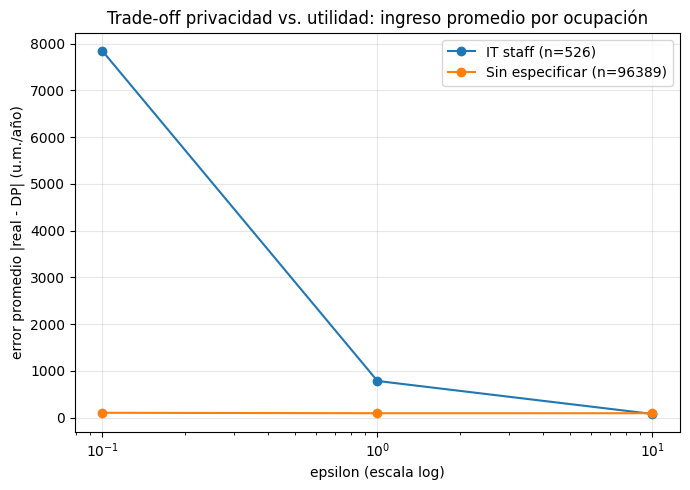

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
for grupo, datos in df_resultados.groupby("grupo"):
    ax.plot(datos["epsilon"], datos["error_promedio"], marker="o", label=f"{grupo} (n={df[df['OCCUPATION_TYPE']==grupo].shape[0]})")

ax.set_xscale("log")
ax.set_xlabel("epsilon (escala log)")
ax.set_ylabel("error promedio |real - DP| (u.m./año)")
ax.set_title("Trade-off privacidad vs. utilidad: ingreso promedio por ocupación")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../docs/assets/dp_tradeoff_ingreso.png", dpi=150)
plt.show()

**Lectura del gráfico:** a mayor epsilon, menos ruido (más utilidad, menos privacidad) — la curva baja. El grupo chico (IT staff) tiene error mucho mayor que el grupo grande (Sin especificar) para el mismo epsilon: proteger grupos pequeños cuesta más utilidad, es el mismo fenómeno de k-anonimato visto en el Lab 10 (grupos chicos = más riesgo de re-identificación = necesitan más protección).

## Fase 3b — Dos fuentes de error: ruido y recorte (revisión cruzada)

En la tabla de la Fase 3 el error de "Sin especificar" queda en ~94 u.m. con cualquier ε. Si fuera ruido, bajaría diez veces con cada salto de ε. `diffprivlib.tools.mean` hace dos cosas: recorta cada valor a los `bounds` (eso mete un **sesgo**) y después suma ruido de Laplace con escala (U − L) / (n · ε) (eso es el **ruido**). Se calculan por separado:

In [11]:
lo, hi = bounds_ingreso
filas = []
for ocup in ["IT staff", "Sin especificar"]:
    valores = df[df["OCCUPATION_TYPE"] == ocup]["AMT_INCOME_TOTAL"]
    n = len(valores)
    fila = {
        "grupo": ocup,
        "n": n,
        "bajo_el_bound": int((valores < lo).sum()),
        "sesgo_recorte": valores.clip(lo, hi).mean() - valores.mean(),
    }
    for eps in epsilons:
        fila[f"escala_ruido_eps_{eps}"] = (hi - lo) / (n * eps)
    filas.append(fila)
pd.DataFrame(filas).set_index("grupo").round(2)

,n,bajo_el_bound,sesgo_recorte,escala_ruido_eps_0.1,escala_ruido_eps_1,escala_ruido_eps_10
grupo,,,,,,
IT staff,526,0,0.0,8127.38,812.74,81.27
Sin especificar,96389,1076,94.3,44.35,4.44,0.44


**Lectura:** en IT staff no hay ningún ingreso fuera de los bounds (sesgo 0) y todo el error es ruido: ~813 u.m. de escala con ε=1, y baja diez veces con cada salto de ε, igual que en la Fase 3. En "Sin especificar" el ruido es mínimo (4,4 u.m. con ε=1), pero 1 076 ingresos están por debajo de 45 000 y, al subirlos al bound, la media se mueve 94,3 u.m.: **ese es el error que se ve en la tabla, y no depende de ε**. Los bounds cambian varianza por sesgo; ε solo controla la varianza.

## Fase 4 — Justificar el ε elegido para producción

Casos reales citados en SEM6, con las cifras oficiales:

- **Apple** (iOS/macOS, *Differential Privacy Overview*): no usa un ε único, sino uno por tipo de dato — Lookup Hints y emojis con ε=4 (hasta 2 donaciones/día), QuickType con ε=8. Un análisis independiente (Tang et al., 2017) estima que, sumando categorías, el presupuesto efectivo por dispositivo llega a ~16/día. Apple mantiene cada ε bajo porque protege telemetría continua (muchos envíos por día, no una sola publicación).
- **Censo de EE. UU. 2020**: presupuesto global oficial, anunciado en junio de 2021 — ε=19.61 para los datos de redistribución de distritos (17.14 para tablas de personas, 2.47 para vivienda). Mucho más alto que Apple porque es una única publicación de estadísticas agregadas, no telemetría repetida.

Nuestro caso (`/api/comunidad`) se parece más al del Censo que al de Apple: es un agregado que se consulta, no telemetría que se envía constantemente. Con los resultados de la Fase 3 (ingreso real de IT staff: 205 490.41 u.m.; de "Sin especificar": 151 818.62 u.m.):

| ε | Error promedio, IT staff (n=526) | Error promedio, Sin especificar (n=96 389) |
|---|---|---|
| 0.1 | 7 843.95 u.m. (≈3.8% del real) | 103.44 u.m. (≈0.07%) |
| 1 | 784.40 u.m. (≈0.38%) | 94.88 u.m. (≈0.06%) |
| 10 | 78.44 u.m. (≈0.04%) | 94.35 u.m. (≈0.06%) |

Para el grupo grande el error ya es despreciable incluso con ε=0.1: con n≈96 000 el ruido de Laplace se diluye solo por el tamaño de la muestra, y los ~94 u.m. que quedan son el sesgo de recorte de la Fase 3b, no ruido. El ε solo cambia algo real para los grupos chicos, y ahí ε=1 ya baja el error a menos de 0.4% — subir a ε=10 solo ahorra ~700 u.m. más, a cambio de una garantía de privacidad diez veces más débil.

**Elegimos ε=1 para producción**: da una garantía mucho más fuerte que el presupuesto del Censo (19.61) y mantiene el error por debajo del 1% en el grupo más chico de la tabla. Lo que sí heredamos del caso del Censo es la lección de fondo: ningún ε arregla un grupo demasiado chico. Grupos por debajo de ~500 personas deberían fusionarse con una categoría vecina (ej. "Sin especificar") antes de publicarse, igual que el k-anonimato del Lab 10 exige un tamaño mínimo de grupo — el ε protege el agregado, no sustituye ese mínimo.

**Ese ε es por publicación, no por consulta.** Los valores ruidosos se calculan una vez y el endpoint devuelve siempre los mismos: si cada consulta sacara ruido nuevo, promediar muchas respuestas lo anularía (composición secuencial). Dentro de una tabla los grupos son disjuntos, así que la tabla completa cuesta ε=1 (composición paralela); publicar las dos tablas, que cubren a las mismas personas, cuesta ε=2.